This notebook is where the classifier modeling occurs.  Here we are attempting to distinguish between the group of viable MVP candidates and the rest of the field so that we may then train on the reduced set of viable players

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

import sys
from pathlib import Path

In [13]:
pd.set_option('display.max_columns', None)

ROOT = Path.cwd()
while not (ROOT / ".git").exists() and ROOT != ROOT.parent:
     ROOT = ROOT.parent
src_path = str(ROOT/"src")
if src_path not in sys.path:
    sys.path.insert(0,src_path)

from config import START_YEAR, END_YEAR, BASE_URL, HTTP_HEADER
import utils

In [14]:
df_tot = utils.player_stat_dataframe(START_YEAR,END_YEAR)
df_new = df_tot.copy()

df_mvp = df_tot.loc[df_tot['MVP'] != 0.0].reset_index(drop=True)
df_mvp.sample(5)

features = ['PTS','W%','FT','eFG%','DRB','AST','BLK','STL','GS','3P']
target = df_mvp.columns[-1]

df_new['RecievedVotes'] = (df_tot['MVP'] != 0.0).astype('int64')
df_new['TradedMidSeason'] = df_tot['Team'].str.endswith('TM').groupby([df_tot['Year'], df_tot['Code']]).transform('any').astype('int64') #adding a col to show of a player got traded

# Classifier testing

In [15]:
print(features)
X = df_new[features]
y = df_new['RecievedVotes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, predictions))

['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P']
Model Accuracy: 98.40%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4853
           1       0.82      0.58      0.68       146

    accuracy                           0.98      4999
   macro avg       0.91      0.79      0.83      4999
weighted avg       0.98      0.98      0.98      4999



In [16]:
# TODO: drop the features that involve NaNs and run LogisticRegression.
print(features)

X = df_new[features]
y = df_new['RecievedVotes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, predictions))

['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P']


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

# Prediction testing

In [17]:
#creating reduced feature set based on heatmaps to get a baseline model working
season_rows=df_new[(df_new['TradedMidSeason']==0) | df_new['Team'].str.endswith('TM')]
rel=season_rows[(season_rows['MP']>=20) & (season_rows['G']>=20)]
vg=rel[rel['MVP']>0]

data=rel.reset_index(drop=True)

X,y,years = data[features],data['MVP'],data['Year']
data['pred']=0.0

for tr,te in LeaveOneGroupOut().split(X,y,groups=years):
    model=HistGradientBoostingRegressor(random_state=12).fit(X.iloc[tr], y.iloc[tr]) #HGBR handles NaNs
    data.loc[te,'pred']=model.predict(X.iloc[te])
    
def evaluate(df,score_col):
    hits,ranks = 0,[]
    for yr, g in df.groupby('Year'):
        actual=g.loc[g['MVP'].idxmax(), 'Code']
        order=g.sort_values(score_col, ascending=False)['Code'].tolist()
        hits += order[0]==actual
        ranks.append(order.index(actual) + 1)
    print(f"{score_col}: picked the MVP in {hits}/{len(ranks)} seasons, "f"real winner's average predicted rank = {np.mean(ranks):.1f}")

evaluate(data, 'pred')
evaluate(data, 'PTS') # naive baseline: 'league's top scorer wins'

pred: picked the MVP in 33/46 seasons, real winner's average predicted rank = 1.7
PTS: picked the MVP in 13/46 seasons, real winner's average predicted rank = 6.5


In [18]:
#checking what the model didn't capture
rows=[]
for yr,g in data.groupby('Year'):
    g=g.sort_values('pred',ascending=False)
    actual=g.loc[g['MVP'].idxmax()]
    if g.iloc[0]['Code']!=actual['Code']:
        rows.append({'Year': yr, 'Predicted': g.iloc[0]['Player'], 'Pred W%': g.iloc[0]['W%'], 'Pred PTS': g.iloc[0]['PTS'],
                     'Actual': actual['Player'], 'Actual W%': actual['W%'], 'Actual PTS': actual['PTS'],
                     'Actual rank': g['Code'].tolist().index(actual['Code'])+ 1})
pd.DataFrame(rows)

,Year,Predicted,Pred W%,Pred PTS,Actual,Actual W%,Actual PTS,Actual rank
0,1981,Larry Bird,0.768293,22.9,Moses Malone,0.560976,31.1,4
1,1986,Larry Bird,0.719512,28.1,Magic Johnson,0.792683,23.9,2
2,1988,Michael Jordan,0.573171,32.5,Magic Johnson,0.695122,22.5,3
3,1989,Michael Jordan,0.670732,33.6,Magic Johnson,0.768293,22.3,3
4,1996,Michael Jordan,0.841463,29.6,Karl Malone,0.780488,27.4,2
5,1997,Karl Malone,0.756098,27.0,Michael Jordan,0.756098,28.7,2
6,2002,Kobe Bryant,0.609756,30.0,Tim Duncan,0.731707,23.3,2
7,2004,Amar'e Stoudemire,0.756098,26.0,Steve Nash,0.756098,15.5,4
8,2005,LeBron James,0.609756,31.4,Steve Nash,0.658537,18.8,10
9,2016,Stephen Curry,0.817073,25.3,Russell Westbrook,0.573171,31.6,5


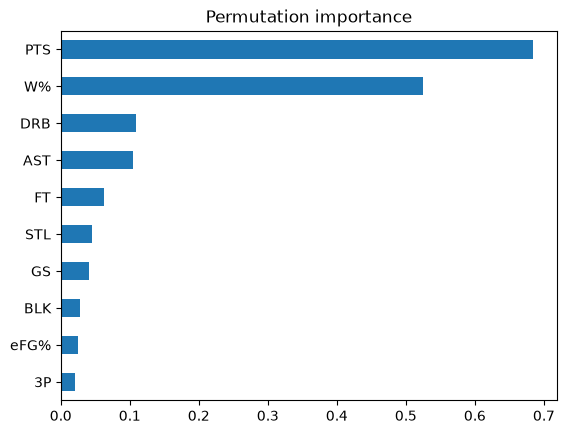

In [19]:
#which features is the mmodel actually using?
model=HistGradientBoostingRegressor(random_state=0).fit(X, y)
imp=permutation_importance(model, X, y, n_repeats=10, random_state=12)
pd.Series(imp.importances_mean, index=features).sort_values().plot.barh()
plt.title('Permutation importance')
plt.show()